# Aula 06 · Edge, Cloud Computing e Gêmeos Digitais
## Onde processar os dados e como testar decisões antes de agir

**ISI022 · Sistemas de Informação e Tecnologias Emergentes**  
**Docente:** Prof. Me. André Cassulino Araújo Souza  
**Duração:** 100 minutos · 60 min de conceitos e demonstrações + 40 min de atividade para entrega  
**Ambiente:** Python 3, Jupyter/VS Code ou Google Colab. Sem credenciais, sensores ou serviços pagos.

**Objetivos de aprendizagem**
1. Justificar a distribuição de processamento entre dispositivo, gateway e nuvem.
2. Calcular latência e volume de dados sem transformar estimativas em garantias.
3. Desenhar um gêmeo com entidades, relações, estado e política de atualização.
4. Comparar cenários What-If e comunicar as limitações do modelo.

**Conexão com as aulas anteriores:** a Aula 04 apresentou CPS e a Aula 05 trabalhou telemetria MQTT. Agora decidimos **onde** tratar os eventos e **como** usá-los para apoiar decisões.

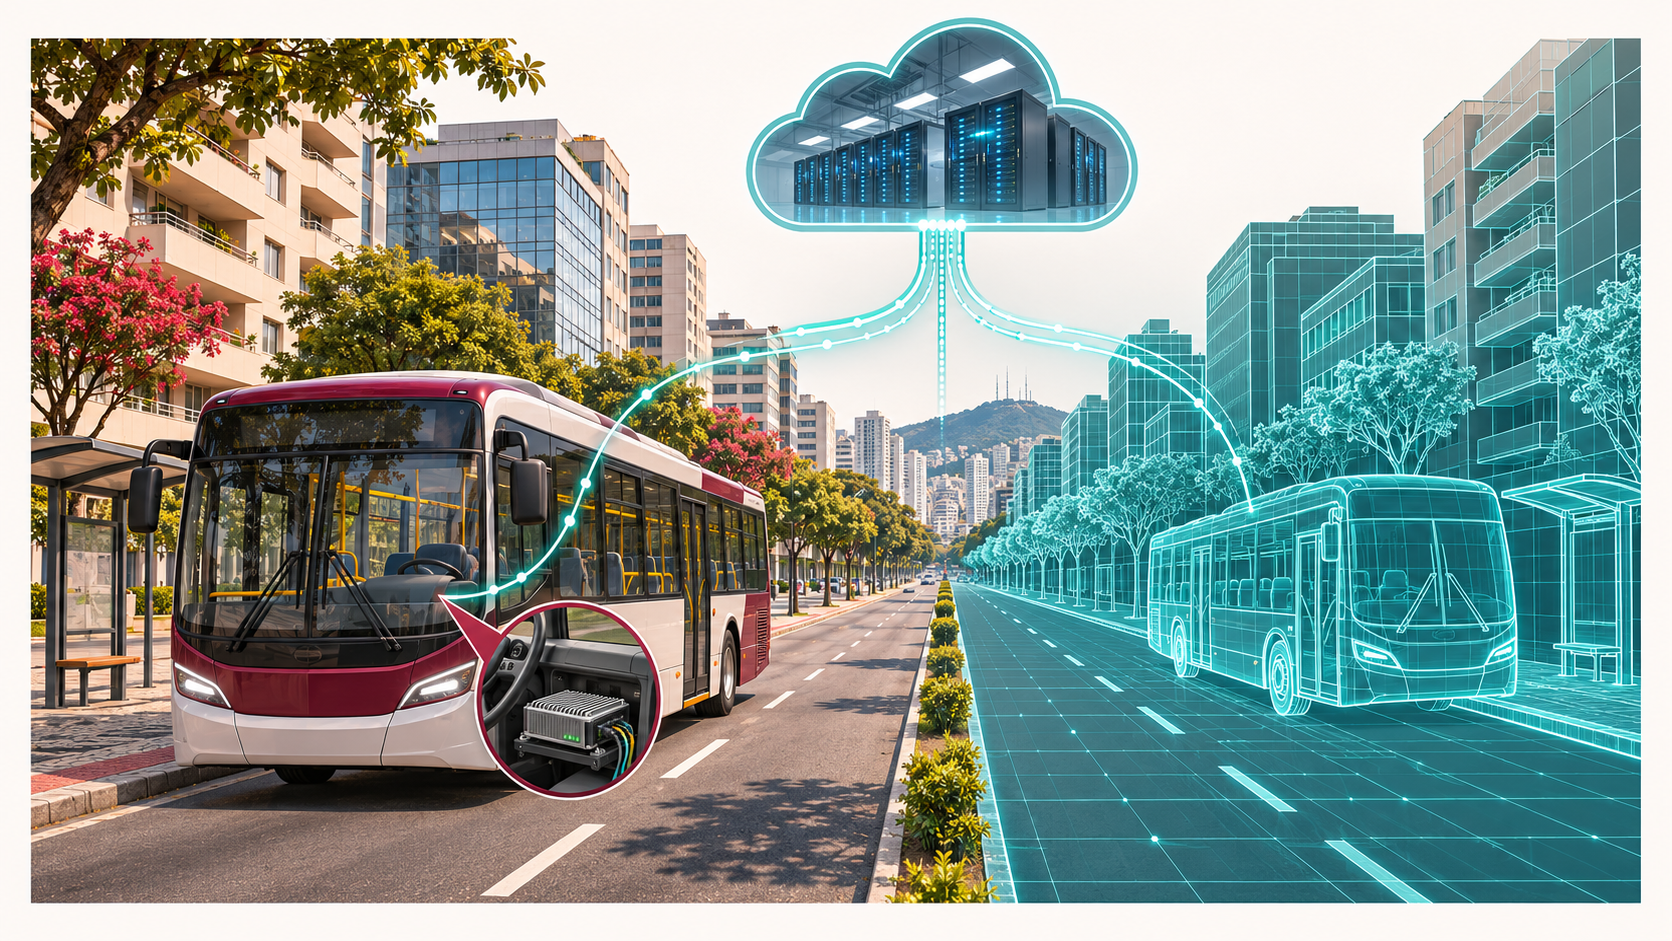

*Ilustração conceitual gerada por IA para esta aula. Não representa uma cidade ou implantação real.*

## Roteiro do encontro

| Etapa | Tempo | Resultado |
|---|---:|---|
| Caso e conceitos Edge/Cloud | 15 min | Requisitos identificados |
| Particionamento, latência e banda | 15 min | Critérios de decisão |
| Desenho e sincronização do gêmeo | 15 min | Modelo de estado e relações |
| Demonstração What-If | 15 min | Cenários comparáveis |
| Atividade final em duplas | 40 min | Notebook preenchido e executado |

### Como usar este caderno
Execute as células de cima para baixo. As imagens estão **incorporadas ao notebook**, e os dados são gerados localmente. As demonstrações já têm saídas salvas. Para editar no Colab, envie este `.ipynb` e execute tudo. Para uso local, instale `numpy`, `pandas`, `matplotlib` e `ipykernel` se necessário. A instalação requer internet, a execução do laboratório não.

As células marcadas **SUA ENTREGA** ficam para a dupla. Os exemplos anteriores são demonstrações e não respondem integralmente ao exercício final.

In [1]:
import math
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('png', 'svg')

plt.rcParams.update({
    'figure.figsize': (10, 4), 'figure.dpi': 120,
    'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.labelcolor': '#334155',
    'axes.prop_cycle': plt.cycler(color=['#8b1e3f', '#0f766e', '#2563eb', '#d97706'])
})
pd.options.display.float_format = '{:,.2f}'.format
print('Ambiente pronto. Todos os números do caso são fictícios e didáticos.')

Ambiente pronto. Todos os números do caso são fictícios e didáticos.


## 1. Caso: frota urbana da Linha L-06

A operadora quer acompanhar **20 ônibus conectados**, dos quais **8 atendem a Linha L-06** no cenário inicial. Cada veículo transmite posição e velocidade, estima ocupação e mede temperatura. A central quer avaliar reforços no horário de pico.

| Função | Requisito didático | Consequência para a arquitetura |
|---|---|---|
| Alerta local de temperatura | Até 100 ms, mesmo sem internet | Decisão local com validação do sensor |
| Atualização de posição no painel | Evento a cada 5 s, dado vencido após 30 s | Qualidade e idade do dado visíveis |
| Ocupação por contagem em vídeo | Imagem permanece no veículo | Enviar contagem agregada e qualidade |
| Histórico de viagem | Consolidação por minuto | Armazenamento durável e reprocessamento |
| Planejamento de frota | Resultado em minutos | Visão conjunta e simulação na nuvem |

**Hipótese de desconexão:** até 10 minutos de rede móvel indisponível. O alerta continua localmente e a telemetria fica em uma fila limitada. O exercício não implementa frenagem, direção autônoma nem controle de segurança veicular.

## 2. Edge e Cloud: funções complementares

**Cloud Computing** oferece recursos computacionais compartilhados e provisionáveis sob demanda. Pode reunir informações de muitas localidades, conservar histórico e executar processamento intensivo. Nuvem não significa um único servidor ou uma única região. [NIST SP 800-145](https://csrc.nist.gov/pubs/sp/800/145/final)

**Edge Computing** posiciona computação próxima à origem dos dados ou dos usuários, por exemplo no computador embarcado ou gateway. Reduz a dependência do caminho remoto, mas exige administração de equipamentos distribuídos. **Fog** costuma descrever camadas intermediárias de computação entre dispositivos e nuvem. [NIST SP 500-325](https://csrc.nist.gov/pubs/sp/500/325/final)

| Critério | Borda | Nuvem |
|---|---|---|
| Visão dos dados | Contexto local | Integração entre veículos e períodos |
| Rede externa | Pode manter funções locais se projetada para isso | Acesso remoto depende da conectividade |
| Capacidade | Limitada por hardware, energia e temperatura | Recursos elásticos sujeitos a custo e configuração |
| Latência | Caminho menor, mas pode haver fila e sobrecarga | Depende de rede, região, fila e aplicação |
| Operação | Atualizações e falhas em muitos dispositivos | Serviços centralizados de gestão e observabilidade |

**Nenhuma posição garante um número de milissegundos.** A garantia depende do sistema inteiro e de medições sob carga. Proximidade também não substitui autenticação, controle de acesso ou atualização de software.



*Arquitetura proposta para o caso. MQTT transporta eventos, enquanto a aplicação decide o que validar, guardar e simular.*

## 3. Latência: o orçamento completo

Para o alerta local, vamos contar desde a aquisição da leitura até a apresentação do alerta:

\[L = L_{aquisição} + L_{rede\ ida} + L_{fila/processamento} + L_{rede\ volta} + L_{alerta}\]

As parcelas abaixo são **hipóteses de uma execução**, em milissegundos. No caminho local, as duas parcelas de rede representam o barramento/rede local. No caminho remoto, representam a conexão com a nuvem. Não confunda latência de processamento com latência fim a fim.

,Borda (ms),Nuvem (ms)
Etapa,,
Aquisição,5,5
Rede de ida,2,45
Fila e processamento,12,20
Rede de volta,2,45
Exibição do alerta,5,5


,Total (ms)
Borda (ms),26
Nuvem (ms),120


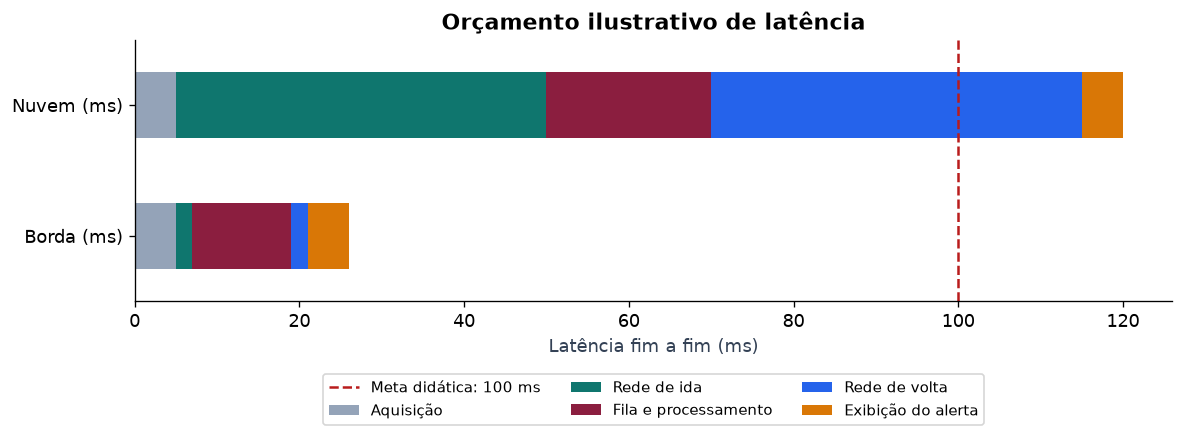

In [2]:
parcelas = pd.DataFrame({
    'Etapa': ['Aquisição', 'Rede de ida', 'Fila e processamento', 'Rede de volta', 'Exibição do alerta'],
    'Borda (ms)': [5, 2, 12, 2, 5],
    'Nuvem (ms)': [5, 45, 20, 45, 5]
}).set_index('Etapa')
display(parcelas)
display(parcelas.sum().rename('Total (ms)').to_frame())
ax = parcelas.T.plot.barh(stacked=True, color=['#94a3b8','#0f766e','#8b1e3f','#2563eb','#d97706'])
ax.axvline(100, color='#b91c1c', linestyle='--', label='Meta didática: 100 ms')
ax.set(xlabel='Latência fim a fim (ms)', title='Orçamento ilustrativo de latência', ylabel='')
ax.legend(bbox_to_anchor=(0.5, -0.25), loc='upper center', ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

O exemplo soma **26 ms na borda** e **120 ms na nuvem**. Nesse orçamento, o caminho remoto não atende à meta de 100 ms. Isso não prova que toda borda atende nem que toda nuvem falha.

### Média, cauda e desconexão
A média pode esconder experiências ruins. O **percentil 95 (p95)** é o valor abaixo do qual estão aproximadamente 95% das observações da amostra. Também devemos medir máximos, violações de prazo e operações sem resposta. A amostra a seguir inclui apenas operações conectadas.

,Média (ms),p95 (ms),Acima de 100 ms (%)
Local,,,
Borda,23.89,31.81,0.00
Nuvem,101.01,173.72,39.50


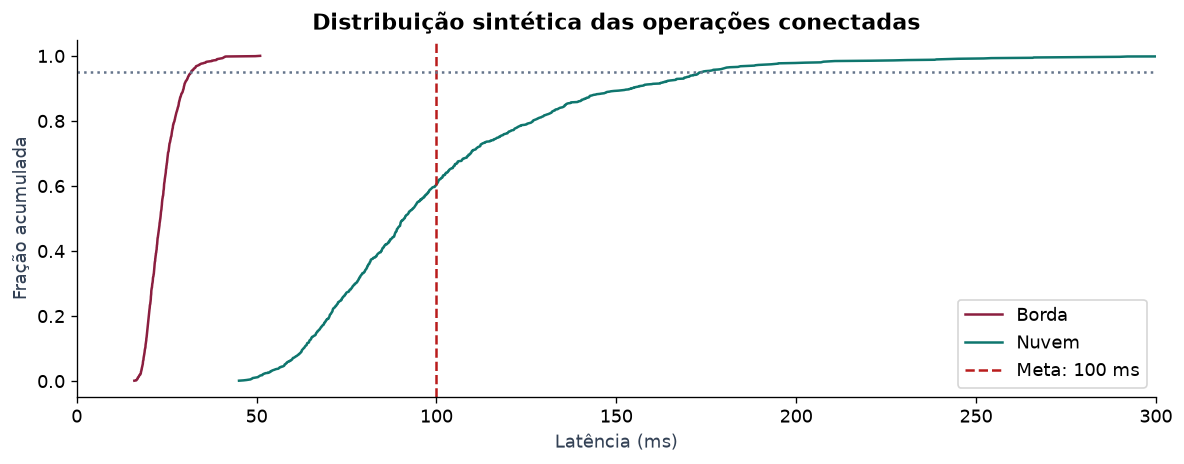

In [3]:
rng = np.random.default_rng(6)
latencias = {
    'Borda': 14 + rng.lognormal(mean=2.2, sigma=0.45, size=1000),
    'Nuvem': 35 + rng.lognormal(mean=4.0, sigma=0.55, size=1000)
}
resumo_latencia = pd.DataFrame([
    {'Local': nome, 'Média (ms)': valores.mean(), 'p95 (ms)': np.percentile(valores,95),
     'Acima de 100 ms (%)': 100*np.mean(valores > 100)}
    for nome, valores in latencias.items()
]).set_index('Local')
display(resumo_latencia)
fig, ax = plt.subplots()
for nome, valores in latencias.items():
    ordenados = np.sort(valores)
    ax.plot(ordenados, np.arange(1,len(valores)+1)/len(valores), label=nome)
ax.axvline(100, color='#b91c1c', linestyle='--', label='Meta: 100 ms')
ax.axhline(.95, color='#64748b', linestyle=':')
ax.set(xlabel='Latência (ms)', ylabel='Fração acumulada', title='Distribuição sintética das operações conectadas', xlim=(0,300))
ax.legend()
plt.tight_layout()
plt.show()

## 4. Particionamento de dados e processamento

Particionar não é apenas escolher onde colocar um banco. Uma mesma informação pode passar por **formas e retenções diferentes** em cada camada.

| Dado ou função | Tratamento local proposto | O que sobe para a nuvem | Retenção didática |
|---|---|---|---|
| Vídeo para estimar ocupação | Inferir contagem sem identificar pessoas | Contagem, horário e qualidade | Quadro só em memória, descarte após inferência |
| Temperatura | Validar, filtrar ruído e alertar | Eventos e resumo por minuto | Buffer circular local de 10 min, histórico por 30 dias |
| Posição/velocidade | Validar coordenadas e guardar durante queda | Evento a cada 5 s | Buffer de 10 min, histórico por 30 dias |
| Estado do veículo | Aplicar regras locais autorizadas | Versão, disponibilidade e diagnóstico | Estado atual e histórico de alterações |
| Planejamento da linha | Aplicar configuração aprovada | Dados agregados da frota | Cenários e parâmetros versionados |

Essas retenções são decisões propostas para o exercício, não prazos legais. Em um projeto real, precisam de justificativa operacional e de privacidade. Identificadores de veículo e localização ainda podem permitir associação com pessoas. Agregar reduz exposição, mas não garante anonimização.

### 4.1 Estimativa de tráfego
Compare duas alternativas por **1 hora de operação de 20 ônibus**: vídeo codificado a 2 Mbit/s por ônibus versus resumo com 300 bytes a cada 5 segundos. O tamanho de 300 bytes já representa a soma dos campos de um resumo. Usaremos unidades decimais: 1 MB = 1.000.000 bytes e 1 Mbit = 1.000.000 bits.

O cálculo é apenas da carga útil. Não inclui MQTT/TCP/TLS, reconexões, retransmissões ou outros fluxos. A redução muda também a informação disponível: os resumos não permitem reconstruir as imagens.

,Resultado
Vídeo (MB),"18,000.00"
Resumos (MB),4.32
Redução (%),99.98


Buffer mínimo para 10 min de resumos: 0.036 MB por ônibus, sem overhead.


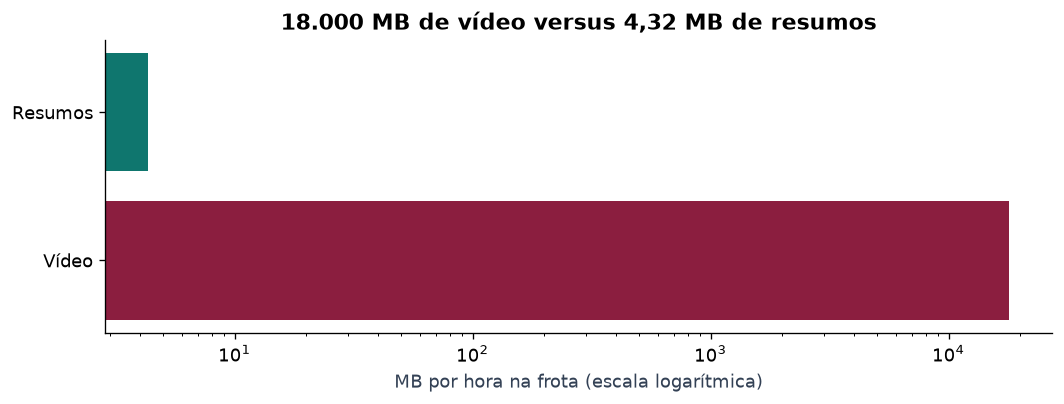

In [4]:
def trafego_frota(onibus=20, horas=1, video_mbps=2, resumo_bytes=300, periodo_s=5):
    if onibus <= 0 or horas <= 0 or periodo_s <= 0 or video_mbps < 0 or resumo_bytes < 0:
        raise ValueError('Verifique os parâmetros de tráfego.')
    segundos = horas * 3600
    video_mb = onibus * segundos * video_mbps / 8
    resumo_mb = onibus * (segundos/periodo_s) * resumo_bytes / 1e6
    return {'Vídeo (MB)': video_mb, 'Resumos (MB)': resumo_mb,
            'Redução (%)': 100*(1-resumo_mb/video_mb) if video_mb else np.nan}

trafego = trafego_frota()
display(pd.Series(trafego).to_frame('Resultado'))
buffer_mb_por_onibus = (10*60/5)*300/1e6
print(f'Buffer mínimo para 10 min de resumos: {buffer_mb_por_onibus:.3f} MB por ônibus, sem overhead.')
fig, ax = plt.subplots(figsize=(9,3.5))
ax.barh(['Vídeo','Resumos'], [trafego['Vídeo (MB)'],trafego['Resumos (MB)']], color=['#8b1e3f','#0f766e'])
ax.set_xscale('log')
ax.set(xlabel='MB por hora na frota (escala logarítmica)', title='18.000 MB de vídeo versus 4,32 MB de resumos')
plt.tight_layout()
plt.show()

### 4.2 Operação durante falhas

O gateway mantém um **buffer persistente e limitado**. Após a reconexão, reenvia eventos preservando o horário original. A nuvem reconhece repetições por `event_id` e não substitui o estado atual por uma medição antiga. Para buffer cheio, nossa proposta é descartar primeiro resumos antigos, reservar espaço para eventos prioritários e registrar a perda.

| Situação | Comportamento esperado |
|---|---|
| Internet indisponível | Alerta local continua, painel remoto sinaliza dado vencido |
| Gateway sem energia | Função local também pode falhar, exigir monitoramento e recuperação |
| Evento duplicado | Não repetir efeitos da aplicação |
| Evento atrasado | Pode servir ao histórico, mas não retrocede o estado atual |
| Comando antigo reaparece | Verificar versão e prazo de validade antes de aplicar |

MQTT QoS 1 admite duplicação. Confirmação no protocolo não comprova processamento de negócio. [OASIS MQTT 5.0](https://docs.oasis-open.org/mqtt/mqtt/v5.0/os/mqtt-v5.0-os.html)

## 5. Matriz de decisão: restrições antes da pontuação

Primeiro elimine alternativas que violam requisitos obrigatórios. Uma média alta não compensa uma função que deixa de operar durante uma desconexão proibida pelo requisito.

**Exemplo: alerta local de temperatura.** A solução exclusivamente remota é inelegível porque a rede pode cair. Para funções sem essa restrição, uma matriz ponderada pode tornar os critérios discutíveis e rastreáveis.

Na escala abaixo, **5 = maior adequação** e **1 = menor adequação**. Para custo/operação, uma nota maior significa menor esforço/custo total estimado, e não hardware mais caro. Pesos e notas são julgamentos ilustrativos deste caso, não benchmarks.

\[S(a) = \sum_i w_i n_{a,i},\quad \sum_i w_i = 1\]

In [5]:
notas = pd.DataFrame({
    'Borda': [5,5,4,2,2],
    'Nuvem': [2,1,2,5,4],
    'Híbrida': [5,5,4,4,2]
}, index=['Latência','Continuidade local','Minimização de dados','Visão da frota','Custo/operação'])
pesos = pd.Series([.30,.25,.20,.15,.10], index=notas.index)
assert np.isclose(pesos.sum(), 1)
elegivel = pd.Series({'Borda': True, 'Nuvem': False, 'Híbrida': True})
resultado_matriz = pd.DataFrame({
    'Pontuação ilustrativa': notas.mul(pesos, axis=0).sum(),
    'Elegível para alerta offline': elegivel
})
display(notas.assign(Peso=pesos))
display(resultado_matriz)
print('A decisão precisa registrar justificativas. Pontuação não substitui teste de requisitos.')

,Borda,Nuvem,Híbrida,Peso
Latência,5,2,5,0.30
Continuidade local,5,1,5,0.25
Minimização de dados,4,2,4,0.20
Visão da frota,2,5,4,0.15
Custo/operação,2,4,2,0.10


,Pontuação ilustrativa,Elegível para alerta offline
Borda,4.05,True
Nuvem,2.40,False
Híbrida,4.35,True


A decisão precisa registrar justificativas. Pontuação não substitui teste de requisitos.


## 6. O que caracteriza o gêmeo digital deste caso?

Adotamos uma definição operacional: uma **representação digital identificável de uma entidade ou processo físico**, atualizada com observações e útil para analisar seu comportamento. O vínculo de atualização precisa declarar frequência e qualidade. Não exige uma visualização 3D. [RFC 9556, seção 4.6](https://www.rfc-editor.org/rfc/rfc9556.html#section-4.6)

| Representação | Alimentação no exemplo | Uso |
|---|---|---|
| Modelo digital estático | Cadastro ou atualização manual | Descrever ônibus e linha |
| Sombra digital | Observações alimentam a representação | Acompanhar estado observado |
| Gêmeo da solução proposta | Estado sincronizado, relações e modelos analíticos | Comparar cenários e apoiar decisões |

A literatura varia no uso desses termos e na exigência de fluxo bidirecional. Nesta aula, **atuação automática não é requisito**: uma recomendação pode passar por uma pessoa. Documente o sentido dos fluxos em vez de deduzir capacidades apenas do nome.

**Estado:** velocidade, ocupação, horário e qualidade mais recentes.  
**Histórico:** sequência de eventos para análise e calibração.  
**Modelo de comportamento:** equações ou simulação que estimam consequências.  
**Cenário:** cópia do estado com hipóteses modificadas, separada do estado observado.



*Desenho de entidades e relações. A separação entre modelos e instâncias também aparece na documentação do Azure Digital Twins.*

### 6.1 Contrato mínimo do evento

```json
{
  "event_id": "BUS-017:boot-a:21",
  "veiculo_id": "BUS-017",
  "seq": 21,
  "t_evento_s": 100,
  "velocidade_kmh": 24.0,
  "ocupacao_pessoas": 42,
  "qualidade": "valida"
}
```

Neste laboratório, o tempo é um número de segundos desde uma origem comum. Em produção, use timestamps com fuso, unidades explícitas, esquema versionado, identificação de reinício e relógios monitorados. `t_recebimento_s` é acrescentado pela ingestão. A sequência do exercício vale para **uma sessão do dispositivo**.

O grafo especifica relações e propriedades, mas requer integração com a ingestão e os serviços analíticos. Um serviço de gêmeos não simula automaticamente qualquer sistema físico. [Azure Digital Twins: grafo e instâncias](https://learn.microsoft.com/en-us/azure/digital-twins/concepts-twins-graph)



*Política ilustrativa para a aula. A atualização de estado e a gravação do histórico são operações diferentes.*

In [6]:
CAPACIDADE_ONIBUS = 80

class GemeoFrota:
    """Modelo didático: uma sessão por dispositivo, memória local e relógios sincronizados."""
    def __init__(self):
        self.estados = {}
        self.vistos = set()
        self.historico = []

    def ingerir(self, evento, recebido_em_s):
        e = copy.deepcopy(evento)
        campos = {'event_id','veiculo_id','seq','t_evento_s','velocidade_kmh','ocupacao_pessoas','qualidade'}
        if not campos <= e.keys():
            return 'rejeitado: esquema incompleto'
        numericos = [e['t_evento_s'], e['velocidade_kmh'], e['ocupacao_pessoas'], recebido_em_s]
        if not all(isinstance(v,(int,float)) and not isinstance(v,bool) and math.isfinite(v) for v in numericos):
            return 'rejeitado: valor não numérico ou não finito'
        if (not isinstance(e['seq'],int) or isinstance(e['seq'],bool) or e['seq'] < 0
                or not isinstance(e['event_id'],str) or not e['event_id']
                or not isinstance(e['veiculo_id'],str) or not e['veiculo_id']):
            return 'rejeitado: identificação ou sequência inválida'
        if (e['qualidade'] != 'valida' or not 0 <= e['velocidade_kmh'] <= 120
                or not 0 <= e['ocupacao_pessoas'] <= CAPACIDADE_ONIBUS
                or not float(e['ocupacao_pessoas']).is_integer()
                or not 0 <= e['t_evento_s'] <= recebido_em_s):
            return 'rejeitado: qualidade, faixa ou horário inválido'
        if e['event_id'] in self.vistos:
            return 'duplicado: ignorado'
        self.vistos.add(e['event_id'])
        e['t_recebimento_s'] = recebido_em_s
        anterior = self.estados.get(e['veiculo_id'])
        novo = anterior is None or (e['t_evento_s'] > anterior['t_evento_s'] and e['seq'] > anterior['seq'])
        self.historico.append({**e, 'aplicado_ao_estado': novo})
        if not novo:
            return 'atrasado: somente histórico'
        self.estados[e['veiculo_id']] = e
        return 'estado atualizado'

    def tabela(self, agora_s, limite_idade_s=30):
        linhas = []
        for estado in self.estados.values():
            idade = agora_s - estado['t_evento_s']
            linhas.append({**estado, 'idade_s': idade,
                           'atualidade': 'atualizado' if 0 <= idade <= limite_idade_s else 'desatualizado'})
        return pd.DataFrame(linhas)

gemeo = GemeoFrota()
eventos = [
    dict(event_id=f'BUS-{i:03d}:a:1', veiculo_id=f'BUS-{i:03d}', seq=1,
         t_evento_s=100, velocidade_kmh=vel, ocupacao_pessoas=40+i, qualidade='valida')
    for i, vel in zip(range(1,9), [22,24,26,23,25,24,22,26])
]
for evento in eventos:
    gemeo.ingerir(evento, recebido_em_s=102)
display(gemeo.tabela(agora_s=110)[['veiculo_id','velocidade_kmh','ocupacao_pessoas','idade_s','atualidade']])

,veiculo_id,velocidade_kmh,ocupacao_pessoas,idade_s,atualidade
0,BUS-001,22,41,10,atualizado
1,BUS-002,24,42,10,atualizado
2,BUS-003,26,43,10,atualizado
3,BUS-004,23,44,10,atualizado
4,BUS-005,25,45,10,atualizado
5,BUS-006,24,46,10,atualizado
6,BUS-007,22,47,10,atualizado
7,BUS-008,26,48,10,atualizado


### 6.2 Experimento: repetição, atraso e dado vencido
Execute a célula. O estado dos ônibus deve continuar na medição de 100 segundos, o evento de 90 segundos pode integrar o histórico, e uma leitura fora da faixa deve ser rejeitada. Avançar o relógio para 140 segundos **não inventa novas observações**.

In [7]:
original = eventos[0]
atrasado = {**original, 'event_id': 'BUS-001:a:0', 'seq': 0, 't_evento_s': 90, 'velocidade_kmh': 10}
invalido = {**original, 'event_id': 'BUS-001:a:2', 'seq': 2, 't_evento_s': 110, 'velocidade_kmh': -5}
print('Repetição:', gemeo.ingerir(original, 112))
print('Fora de ordem:', gemeo.ingerir(atrasado, 113))
print('Faixa inválida:', gemeo.ingerir(invalido, 114))
display(gemeo.tabela(140)[['veiculo_id','velocidade_kmh','t_evento_s','idade_s','atualidade']])
assert gemeo.estados['BUS-001']['t_evento_s'] == 100
assert len(gemeo.historico) == 9
assert (gemeo.tabela(140)['atualidade'] == 'desatualizado').all()
print('Conferência: evento antigo não retrocedeu o estado e a desconexão ficou visível.')

Repetição: duplicado: ignorado
Fora de ordem: atrasado: somente histórico
Faixa inválida: rejeitado: qualidade, faixa ou horário inválido


,veiculo_id,velocidade_kmh,t_evento_s,idade_s,atualidade
0,BUS-001,22,100,40,desatualizado
1,BUS-002,24,100,40,desatualizado
2,BUS-003,26,100,40,desatualizado
3,BUS-004,23,100,40,desatualizado
4,BUS-005,25,100,40,desatualizado
5,BUS-006,24,100,40,desatualizado
6,BUS-007,22,100,40,desatualizado
7,BUS-008,26,100,40,desatualizado


Conferência: evento antigo não retrocedeu o estado e a desconexão ficou visível.


## 7. What-If: avaliação paramétrica da Linha L-06

Vamos criar uma **simulação paramétrica determinística**, não uma previsão operacional nem um simulador de tráfego microscópico. O modelo calcula o equilíbrio aproximado da linha para cada combinação de parâmetros.

| Parâmetro | Valor inicial | Interpretação |
|---|---:|---|
| Distância do ciclo | 12 km | Percurso completo até o veículo voltar a poder partir |
| Velocidade em movimento | 24 km/h | Desconsidera tempos parado |
| Tempo total em paradas | 12 min | Soma por ciclo |
| Recuperação no terminal | 6 min | Soma por ciclo |
| Frota ativa | 8 ônibus | Veículos distribuídos regularmente |
| Capacidade por veículo | 80 pessoas | Usada no trecho crítico, por passagem |
| Demanda | 600 pessoas/h | Fluxo no mesmo trecho/sentido de referência |

\[T_{ciclo} = 60D/v + T_{paradas} + T_{terminal}\]
\[H = T_{ciclo}/N,\quad C = 60K/H,\quad W_{ideal} = H/2\]

`H` é o intervalo entre ônibus em minutos, `C` é a capacidade nominal por hora e `W` é a espera média idealizada. `K` é a capacidade por ônibus e `N` a frota ativa. O quociente `demanda/C` mede **pressão sobre a capacidade**, não ocupação observada dentro de cada ônibus.

**Hipóteses:** distribuição regular da frota, chegadas uniformes de passageiros, capacidade utilizável no trecho de referência e tempos de parada fixos. Quando demanda ≥ capacidade, a espera `H/2` **não representa a espera real**, pois pode haver fila crescente e recusa de embarque. Mesmo abaixo da capacidade nominal, irregularidade e ônibus já cheios podem invalidar a aproximação.



*O fluxo separa observação, hipótese e decisão.*

In [8]:
def avaliar_cenario(nome, frota, velocidade_kmh, demanda_h,
                    distancia_km=12, paradas_min=12, terminal_min=6, capacidade=80):
    valores = [velocidade_kmh, demanda_h, distancia_km, paradas_min, terminal_min, capacidade]
    if (not isinstance(frota,int) or isinstance(frota,bool) or frota <= 0
            or not all(isinstance(x,(int,float)) and math.isfinite(x) for x in valores)
            or velocidade_kmh <= 0 or distancia_km <= 0 or capacidade <= 0
            or min(demanda_h,paradas_min,terminal_min) < 0):
        raise ValueError('Frota inteira positiva, velocidade/distância/capacidade positivas e demais parâmetros não negativos.')
    ciclo = 60*distancia_km/velocidade_kmh + paradas_min + terminal_min
    intervalo = ciclo/frota
    capacidade_h = 60*capacidade/intervalo
    return {'Cenário': nome, 'Frota': frota, 'Velocidade (km/h)': velocidade_kmh,
            'Demanda (pess./h)': demanda_h, 'Ciclo (min)': ciclo, 'Intervalo (min)': intervalo,
            'Capacidade (pess./h)': capacidade_h, 'Pressão (%)': 100*demanda_h/capacidade_h,
            'Espera ideal (min)': intervalo/2,
            'Espera interpretável': demanda_h < capacidade_h}

# Leitura do gêmeo no instante de referência, antes do envelhecimento para 140 s.
snapshot = copy.deepcopy(gemeo.tabela(agora_s=110))
validos = snapshot[snapshot['atualidade'] == 'atualizado']
assert len(validos) == 8, 'Precisamos de cobertura de todos os veículos neste exemplo.'
velocidade_base = float(validos['velocidade_kmh'].median())
print(f'Proxy didática da velocidade: mediana das leituras recentes = {velocidade_base:.1f} km/h')
print('Em produção, estimar velocidade de percurso com trajetórias e tempos, não só uma fotografia instantânea.')

cenarios = pd.DataFrame([
    avaliar_cenario('Base', 8, velocidade_base, 600),
    avaliar_cenario('Congestionamento', 8, 16, 600),
    avaliar_cenario('Congestionamento + pico', 8, 16, 760),
    avaliar_cenario('Reforço no pico', 11, 16, 760)
]).set_index('Cenário')
display(cenarios)

Proxy didática da velocidade: mediana das leituras recentes = 24.0 km/h
Em produção, estimar velocidade de percurso com trajetórias e tempos, não só uma fotografia instantânea.


,Frota,Velocidade (km/h),Demanda (pess./h),Ciclo (min),Intervalo (min),Capacidade (pess./h),Pressão (%),Espera ideal (min),Espera interpretável
Cenário,,,,,,,,,
Base,8,24.00,600,48.00,6.00,800.00,75.00,3.00,True
Congestionamento,8,16.00,600,63.00,7.88,609.52,98.44,3.94,True
Congestionamento + pico,8,16.00,760,63.00,7.88,609.52,124.69,3.94,False
Reforço no pico,11,16.00,760,63.00,5.73,838.10,90.68,2.86,True


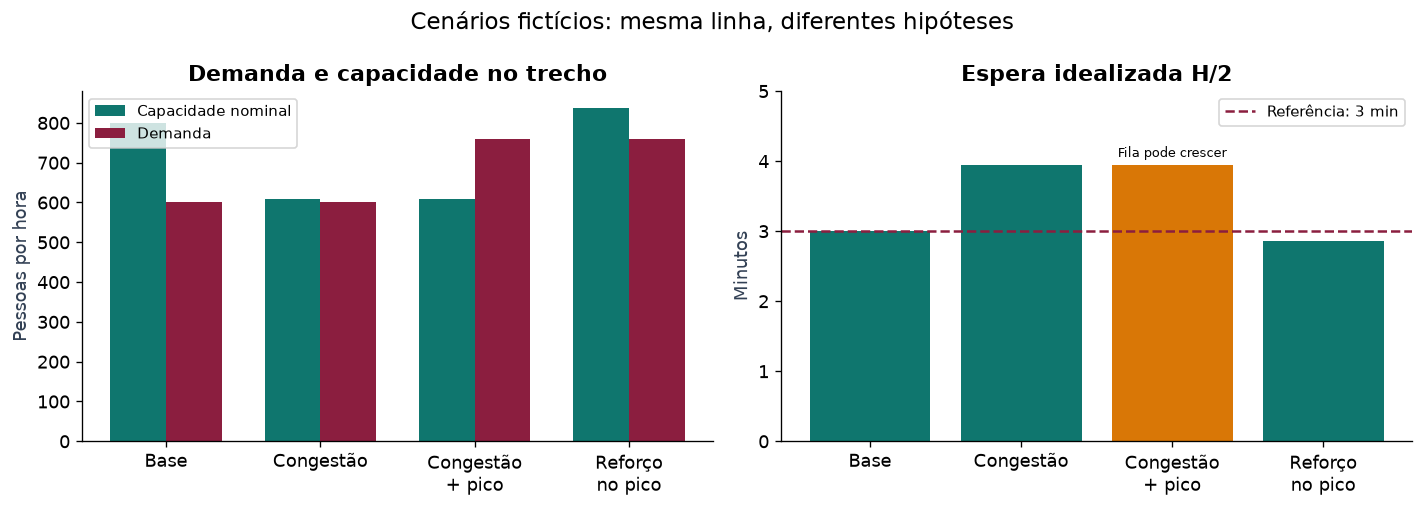

In [9]:
fig, axes = plt.subplots(1,2, figsize=(12,4.3))
pos = np.arange(len(cenarios))
nomes = ['Base','Congestão','Congestão\n+ pico','Reforço\nno pico']
axes[0].bar(pos-.18, cenarios['Capacidade (pess./h)'], width=.36, label='Capacidade nominal', color='#0f766e')
axes[0].bar(pos+.18, cenarios['Demanda (pess./h)'], width=.36, label='Demanda', color='#8b1e3f')
axes[0].set(title='Demanda e capacidade no trecho', ylabel='Pessoas por hora', xticks=pos, xticklabels=nomes)
axes[0].legend(fontsize=9)
cores = ['#0f766e' if ok else '#d97706' for ok in cenarios['Espera interpretável']]
axes[1].bar(pos, cenarios['Espera ideal (min)'], color=cores)
axes[1].axhline(3, color='#8b1e3f', linestyle='--', label='Referência: 3 min')
axes[1].set(title='Espera idealizada H/2', ylabel='Minutos', xticks=pos, xticklabels=nomes)
axes[1].legend(fontsize=9)
for i, ok in enumerate(cenarios['Espera interpretável']):
    if not ok:
        axes[1].text(i, cenarios.iloc[i]['Espera ideal (min)']+.12, 'Fila pode crescer', ha='center', fontsize=8)
axes[1].set_ylim(0,5)
fig.suptitle('Cenários fictícios: mesma linha, diferentes hipóteses', fontsize=14)
plt.tight_layout()
plt.show()

### Leitura dos resultados
Na base, o ciclo leva **48 min**, o intervalo é **6 min** e a capacidade nominal é **800 pessoas/h**. Com velocidade de 16 km/h, o ciclo aumenta para **63 min**, e a capacidade com 8 veículos cai para aproximadamente **610 pessoas/h**. Com 760 pessoas/h, a demanda excede essa capacidade.

Com 11 veículos no pico, o modelo aponta intervalo de aproximadamente **5,73 min**, capacidade de **838 pessoas/h** e espera ideal de **2,86 min**. Isso melhora os indicadores nas hipóteses adotadas, mas ainda exige conferir disponibilidade de veículos, custo, paradas e variabilidade. A comparação congestionamento versus pico mantém a velocidade e altera apenas a demanda.

### 7.1 Sensibilidade
Uma decisão precisa resistir a mudanças plausíveis. A curva a seguir varia apenas a frota, mantendo velocidade de 16 km/h e demanda de 760 pessoas/h. A relação não garante que adicionar ônibus sempre resolva problemas reais, como congestionamento nas paradas.

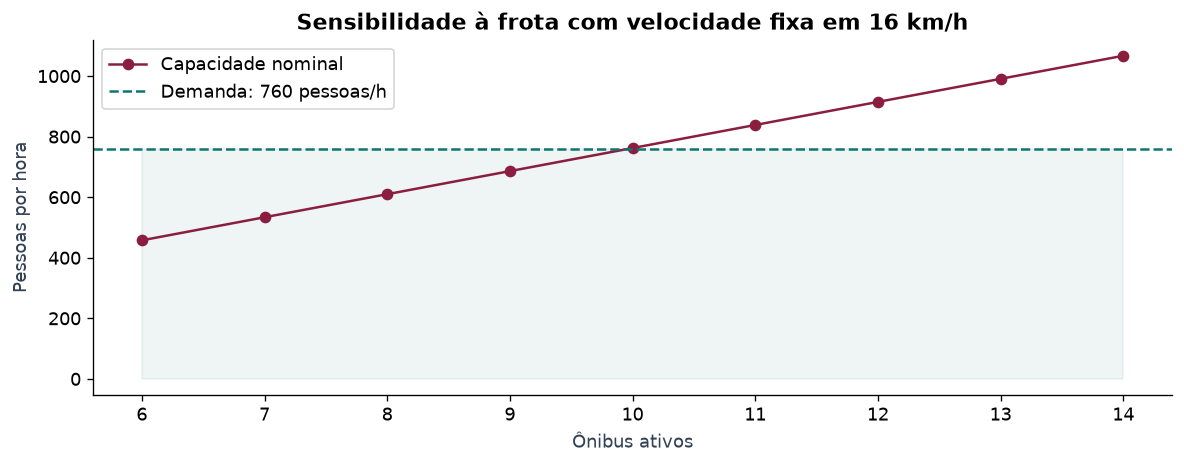

In [10]:
sensibilidade = pd.DataFrame([
    avaliar_cenario(str(n), n, 16, 760) for n in range(6,15)
])
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(sensibilidade['Frota'], sensibilidade['Capacidade (pess./h)'], marker='o', label='Capacidade nominal')
ax.axhline(760, color='#0f766e', linestyle='--', label='Demanda: 760 pessoas/h')
ax.fill_between(sensibilidade['Frota'], 0, 760, color='#0f766e', alpha=.07)
ax.set(xlabel='Ônibus ativos', ylabel='Pessoas por hora', title='Sensibilidade à frota com velocidade fixa em 16 km/h', xticks=range(6,15))
ax.legend()
plt.tight_layout()
plt.show()

## 8. Limites e validação do gêmeo

| Possível erro | Impacto | Como investigar |
|---|---|---|
| Sensor descalibrado | Estado e projeções incorretos | Comparar com referência e registrar incerteza |
| Estado vencido | Cenário parte de condições antigas | Exibir idade e cobertura dos dados |
| Velocidade instantânea como velocidade do ciclo | Viés no tempo de viagem | Estimar por segmentos e validar com trajetórias |
| Tempo parado fixo | Subestimação em horário de pico | Modelar embarque e desembarque |
| Frota irregular ou ônibus em comboio | Espera maior que H/2 | Medir distribuição de intervalos |
| Modelo sem capacidade de embarque disponível | Falsa suficiência da oferta | Modelar carga por trecho e filas |

**Validação mínima:** separar observações usadas na calibração das usadas na avaliação, comparar tempos previstos com realizados e documentar o erro. Um erro médio baixo não elimina erros grandes em situações críticas. Dados sintéticos conferem o funcionamento do código, não validam a realidade urbana.

**Segurança operacional proposta:** autenticação de dispositivos, TLS, autorização por tópico, separação entre telemetria e comandos, configuração assinada/versionada e trilha de auditoria. O caminho de comandos deve exigir autorização e expiração. Essas medidas são escolhas de arquitetura a discutir, não uma implantação pronta.

## 9. Síntese para revisão

- A borda atende funções próximas ao evento, respeitando os limites do equipamento.
- A nuvem reúne histórico e contexto de múltiplos ativos.
- A matriz registra requisitos, critérios, notas e justificativas.
- O gêmeo liga identidade, relações, observações e qualidade do estado.
- O What-If compara hipóteses e produz estimativas condicionadas ao modelo.

**Questões para discussão:**
1. O painel pode dizer que um ônibus está em uma posição sem informar quando recebeu a leitura?
2. Em que situação uma pontuação ponderada esconderia uma restrição obrigatória?
3. Por que 99,976% de redução na carga útil não significa 99,976% de redução no custo total?
4. Que informação adicional é necessária para substituir a espera H/2 por uma espera mais realista?

## 10. Referências e créditos

1. **NIST SP 800-145.** [The NIST Definition of Cloud Computing](https://csrc.nist.gov/pubs/sp/800/145/final), 2011. Definição e características de nuvem.
2. **NIST SP 500-325.** [Fog Computing Conceptual Model](https://csrc.nist.gov/pubs/sp/500/325/final), 2018. Camadas entre dispositivo e nuvem.
3. **IRTF, RFC 9556.** [Internet of Things (IoT) Edge Challenges and Functions](https://www.rfc-editor.org/rfc/rfc9556.html), 2024. Documento informativo sobre requisitos de borda e ambientes de simulação.
4. **Microsoft Learn.** [Digital twins and their twin graph](https://learn.microsoft.com/en-us/azure/digital-twins/concepts-twins-graph). Modelos, instâncias e relações.
5. **OASIS.** [MQTT Version 5.0](https://docs.oasis-open.org/mqtt/mqtt/v5.0/os/mqtt-v5.0-os.html), 2019, seção 4.3. Semântica dos níveis de QoS.

Consulta em **05/11/2026**. As arquiteturas, notas da matriz, medições sintéticas, parâmetros de transporte e enunciado são exemplos didáticos próprios. Diagramas vetoriais autorais, editáveis nos arquivos da aula. Capa conceitual gerada pela ferramenta integrada de imagens. O registro do prompt está em `images/aula06/CREDITOS.md` no repositório.

# 11. Atividade final para entrega · Operação da Linha L-06

**Modalidade:** dupla · **Tempo:** 40 minutos · **Entrega ao final da aula no Teams**  
**Arquivo:** `Aula06_Nome1_Nome2.ipynb`, com nomes, respostas e saídas de execução preservadas. Não é necessário um relatório separado. Insira o desenho no próprio notebook como imagem anexada ou diagrama textual legível.

## Problema
A Linha L-06 terá **demanda de 900 pessoas/h** e velocidade em movimento de **18 km/h**. A operadora pode manter de **8 a 12 ônibus** ativos. O ciclo completo tem **12 km**, soma **12 min em paradas** e **6 min no terminal**. Cada ônibus comporta **80 pessoas** no trecho de referência.

Metas didáticas: **capacidade nominal ≥ demanda** e **espera ideal ≤ 3 min**. A internet pode ficar indisponível por **10 min**. Um alerta local de temperatura deve ocorrer em até **100 ms**, inclusive durante essa queda. A posição é publicada a cada **5 s** e o painel deve marcar dados com mais de **30 s** como desatualizados. O vídeo bruto usado na contagem não pode sair do veículo.

Todos os requisitos e dados são fictícios. O exercício avalia coerência e justificativa, não contratação de serviços reais.

## A. Matriz de particionamento · 10 min · 3,0 pontos
Preencha **pelo menos 5 linhas**: temperatura/alerta, posição, vídeo/ocupação, histórico de viagem e planejamento de frota. Para cada uma, informe:

1. Dado ou função e requisito de prazo/frequência.
2. O que processa na borda e o que processa na nuvem.
3. Conteúdo transmitido e política de retenção.
4. Comportamento offline e gatilho de alerta.
5. Justificativa, incluindo privacidade quando pertinente.

Identifique **duas restrições obrigatórias** que não podem ser compensadas por pontuação. Se usar notas/pesos, explique a escala e normalize os pesos. A matriz de particionamento é obrigatória, a matriz ponderada é opcional.

## B. Desenho do gêmeo digital · 8 min · 2,0 pontos
Represente **Ônibus, Linha e Parada**, com identificadores, **pelo menos duas relações nomeadas** e propriedades com unidades. Mostre o caminho sensor/gateway/ingestão/gêmeo/simulação, indicando onde cada função executa.

Especifique horário da medição, horário de recebimento, regra de dado vencido, tratamento de evento duplicado e de evento fora de ordem. Identifique quem pode autorizar uma mudança na operação. Você pode usar um desenho feito em ferramenta externa e anexá-lo ou completar o diagrama textual abaixo.

## C. Simulação What-If · 14 min · 3,0 pontos
Use `avaliar_cenario` para comparar **8, 10 e 12 ônibus** com os parâmetros do problema. Produza uma tabela e **um gráfico** com capacidade versus demanda. Registre ciclo, intervalo, capacidade, pressão e espera ideal.

Depois, encontre a **menor frota inteira entre 8 e 12** que atende às duas metas. Verifique demanda **10% maior** mantendo essa frota e velocidade. Explique se a recomendação resiste ao aumento. Não use H/2 como espera real quando a demanda atingir ou superar a capacidade.

## D. Recomendação e conferência · 8 min · 2,0 pontos
Escreva de **8 a 12 linhas**: arquitetura escolhida, frota recomendada, números que sustentam a escolha, tratamento da queda de rede e **duas limitações do modelo**. Explique por que o gêmeo precisa de medições recentes e por que a simulação não autoriza automaticamente uma ação física.

Antes de entregar, reinicie o kernel, execute tudo, confira as saídas e salve. A dupla deve conseguir explicar as escolhas e identificar quais números são observados, assumidos ou calculados.

## SUA ENTREGA · Identificação e matriz
**Integrantes:** PREENCHER  
**Turma:** PREENCHER

| Dado/função | Prazo/frequência | Borda | Nuvem | Transmissão/retenção | Offline e gatilho | Justificativa |
|---|---|---|---|---|---|---|
| Temperatura/alerta | | | | | | |
| Posição | | | | | | |
| Vídeo/ocupação | | | | | | |
| Histórico de viagem | | | | | | |
| Planejamento | | | | | | |

**Duas restrições obrigatórias e suas consequências:** PREENCHER.

## SUA ENTREGA · Desenho e sincronização
Substitua o esquema por seu desenho ou complete os rótulos e propriedades:

```text
[Sensor: ...] -- evento ... --> [Gateway: ...] -- ... --> [Ingestão: ...]
                                                           |
                                                           v
[Ônibus ID: ...] -- relação: ... --> [Linha ID: ...] -- relação: ... --> [Parada ID: ...]
                                                           |
                                                           v
                                                 [Cópia para cenário: ...]
```

**Propriedades e unidades:** PREENCHER.  
**t_evento, t_recebimento e limite de idade:** PREENCHER.  
**Eventos duplicados e fora de ordem:** PREENCHER.  
**Quem autoriza a mudança física:** PREENCHER.

In [11]:
# SUA ENTREGA · Complete a lista com chamadas de avaliar_cenario.
# Exemplo de assinatura: avaliar_cenario(nome, frota, velocidade_kmh, demanda_h)
# Use os números do enunciado. Os valores padrão de distância/paradas/terminal/capacidade já correspondem ao caso.
minhas_simulacoes = [
    # avaliar_cenario(...),
]
minha_tabela = pd.DataFrame(minhas_simulacoes)
if minha_tabela.empty:
    print('Preencha os cenários de 8, 10 e 12 ônibus e execute novamente.')
else:
    display(minha_tabela)
    # TODO: criar gráfico de capacidade versus demanda, com título e unidades.

Preencha os cenários de 8, 10 e 12 ônibus e execute novamente.


In [12]:
# SUA ENTREGA · Procure a menor frota inteira que atende às duas metas.
# Compare capacidade >= demanda e espera ideal <= 3.
# Depois teste essa frota com demanda 10% maior e registre os indicadores.
frota_recomendada = None  # Substitua pela escolha calculada.
cenario_sensibilidade = None  # Substitua por uma chamada de avaliar_cenario.

## SUA ENTREGA · Parecer final
**Recomendação de 8 a 12 linhas:** PREENCHER.

**Limitação 1 e dado adicional necessário:** PREENCHER.  
**Limitação 2 e dado adicional necessário:** PREENCHER.

### Checklist e critérios de avaliação

| Critério | Pontos | Evidência esperada |
|---|---:|---|
| Matriz | 3,0 | Cinco funções, prazos, particionamento, offline, retenção e justificativas |
| Desenho | 2,0 | Entidades, relações, unidades, fluxos e sincronização |
| What-If | 3,0 | Comparação, gráfico, menor frota e aumento de demanda |
| Parecer | 2,0 | Decisão sustentada, limitações e notebook executado |

- [ ] Nomes e turma preenchidos.
- [ ] Matriz e desenho completos.
- [ ] Cenários e gráfico visíveis, com unidades.
- [ ] Sensibilidade de +10% e limitações discutidas.
- [ ] Células executadas sem erro e notebook salvo no formato solicitado.